# D04 · Compression, validity and intended action
Compare storage and quality before and after quantization, inspect valid-but-unintended actions, and exercise the actual simulator gate without loading a language model.
**Prerequisites:** basic Python and the [learning guide](../docs/LEARNING_GUIDE.md).
**Evidence boundary:** the charts read the recorded October 26, 2026 experiments by default. Running this notebook recomputes plots and teaching calculations; it does not retrain a model or run new model inference. Illustrative examples below are labeled separately. The [notebook guide](README.md) explains setup, provenance, and how to export your own completed runs.

## Load the evidence
Run all cells in order. The loader prints the run IDs, dates, seeds and scope. A custom export does not automatically rewrite the historical interpretation in this lesson.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/lab.py").is_file() and (p / "src/ml_training").is_dir())
for folder in [ROOT / "notebooks", ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from lab import load_demo, style, grouped_bars
style()

# None uses the compact checked-in snapshot. To inspect a new export, set an
# explicit path, e.g. ROOT / "artifacts/my-notebook-results.json". Missing files fail.
SNAPSHOT_PATH = None
d = load_demo("D04", SNAPSHOT_PATH)

D04 | recorded experiment data | recorded_results.json
Recorded local educational experiments. Inspect run dates, seeds and source manifests before comparing results. No production or physical-device validation.
Run: artifacts/edge/local-s41-20261026T175513Z-eae775 | recorded: 20261026T175513Z | seed: 41


## The concept
Quantization represents weights with fewer bits plus scales/metadata. It can reduce storage and memory, but its effect on task accuracy must be measured. Local placement is a separate choice from training and numerical representation.
A dispatcher can enforce an allowed API range. It cannot infer whether a range-valid command matches the user's intent. The original experiment used a simulated thermostat, not physical hardware.

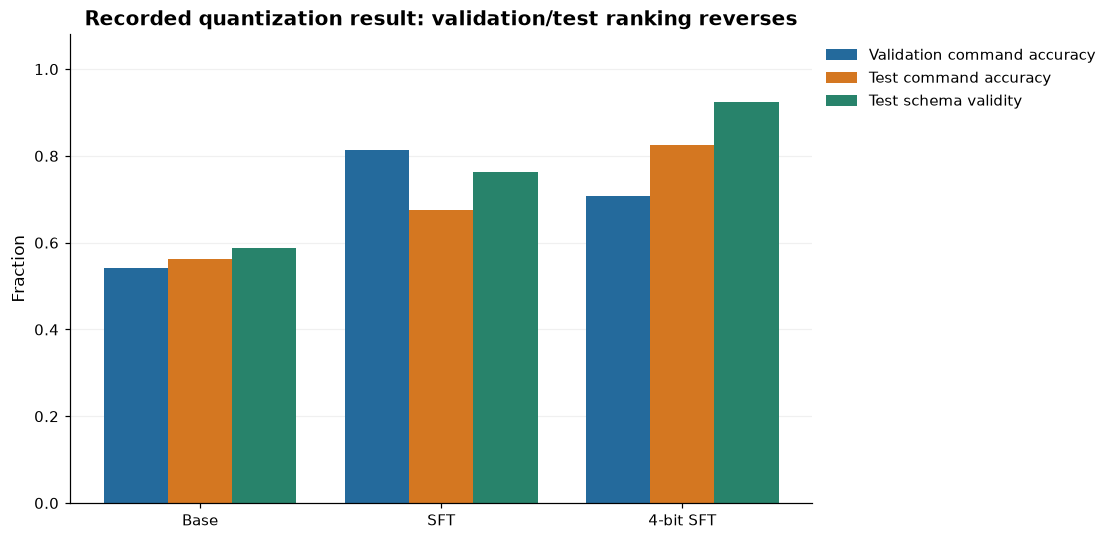

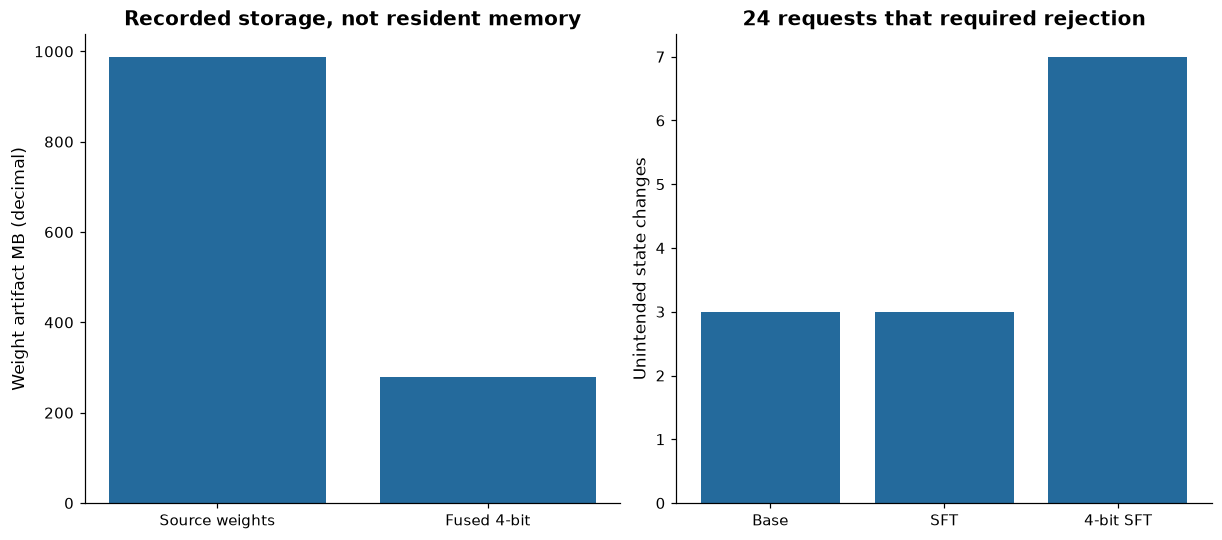

In [2]:
variants = ['base', 'tuned', 'quantized_tuned']
grouped_bars(['Base', 'SFT', '4-bit SFT'], {
    'Validation command accuracy': [d['selection']['validation'][v]['joint_accuracy'] for v in variants],
    'Test command accuracy': [d['metrics'][v]['joint_accuracy'] for v in variants],
    'Test schema validity': [d['metrics'][v]['schema_validity'] for v in variants],
}, title='Recorded quantization result: validation/test ranking reverses')
plt.show()
q = d['quantization']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout='constrained')
axes[0].bar(['Source weights', 'Fused 4-bit'], [q['base_model_bytes']/1e6, q['model_bytes']/1e6])
axes[0].set(ylabel='Weight artifact MB (decimal)', title='Recorded storage, not resident memory')
axes[1].bar(['Base', 'SFT', '4-bit SFT'], [d['rejection_mutations'][v]['mutations'] for v in variants])
axes[1].set(ylabel='Unintended state changes', title='24 requests that required rejection')
plt.show()

### Change a proposed command
These are **illustrative commands executed by the real deterministic simulator**. No physical device is connected. Try a valid temperature, an out-of-range value, and a different valid temperature than the request intended. The last case passes range checks while violating intent.

In [3]:
from ml_training.device_data import dispatch
intended_celsius = 22
proposed_celsius = 26  # Try 22 or 35.
state = {'celsius': 20, 'jobs': []}
try:
    after = dispatch({'action': 'set_temperature', 'args': {'celsius': proposed_celsius}}, state)
    print('Gate accepted. Matches this illustrative intent:', after['celsius'] == intended_celsius)
    print('Before:', state, '| After:', after)
except ValueError as error:
    print('Gate rejected:', error, '| State remains:', state)

Gate accepted. Matches this illustrative intent: False
Before: {'celsius': 20, 'jobs': []} | After: {'celsius': 26, 'jobs': []}


**Interpretation check:** the quantized model has better test command accuracy here, yet validation selected the unquantized model and quantization increases unintended mutations on rejection requests. Do not change the frozen model choice using test results. This single seed cannot establish that quantization generally improves quality.

## What you learned and when to use it
Local models can support network independence and placement constraints. Qualification still needs actual target-device memory, startup, thermal and task measurements. A deterministic command UI or small classifier may be enough; runtime validity is narrower than intent correctness.
**Architecture exercise:** state a quality floor, a simpler alternative, and the evidence that would make you reject this approach. Compare your answer with the [decision guide](../docs/ARCHITECTURE_DECISION_GUIDE.md#d04--run-a-compact-model-locally).
**Train or run the actual model:** follow the [D04 tutorial](../docs/SLM_DEMOS.md#d04-local-model-and-simulated-device). Training stays in its existing locked environment; this notebook stays light enough to run without model downloads.
[All visual lessons](README.md) · [Production tradeoffs](../docs/PRODUCTION_TRADEOFFS.md)